---
title: "Temperature, Ideal Gas and Kinetic Theory — Level 2"
short_title: "01 Ideal Gas & Kinetic Theory"
numbering:
  heading_2: true
  equation: true
---

# Temperature, Ideal Gas and Kinetic Theory

:::{seealso} Math for this topic
- [T-M2: Gaussian, Gamma and quantum-statistics integrals](../math/02-gaussian-gamma-integrals.ipynb)
- [T-M1: Counting, probability and Stirling's approximation](../math/01-counting-probability-stirling.ipynb)
- [M2: Coordinates, integrals and the delta function](../../level2-book/math/02-coordinates-integrals-delta.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 17–18 | PV = nRT, equipartition, rms speeds |
| **2** | **Schroeder, ch. 1** | **Maxwell speed distribution, equipartition from the Boltzmann factor** |
| 3 | Pathria, ch. 1 and 3 | Phase-space counting, Gibbs paradox, canonical partition function |

The new skill at this level: deriving the gas laws and speed distribution from molecules, instead of taking them as given

Math for this topic: T-M2 (Gaussian and Gamma integrals), T-M1 (probability) and mechanics M2 (multiple integrals).
:::

Workbook example ladder: heat capacity of a gas in a box → moments of the Maxwell distribution → partition function of an ideal gas with the Gibbs factor. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [T-M3: Exact differentials and thermodynamic calculus](../math/03-thermodynamic-calculus.ipynb), the math for the next chapter. If you miss a part, study just the section it names and try that problem again.

1. **Temperature**

   (a) Find the number density of an ideal gas at 1 atm and 273 K.

   (b) What does it mean for two systems to have the same temperature?

2. **The Ideal Gas Law from Molecules**

   (a) Starting from $PV = Nm\overline{v_x^2}$, show that the average kinetic energy per molecule is $\tfrac32kT$.

   (b) Find $v_{\text{rms}}$ for N₂ (28 u) at 300 K.

3. **Equipartition**

   (a) Find the thermal energy and $C_V$ of 1 mol of a diatomic gas at room temperature.

   (b) Why doesn't vibration contribute at room temperature?

   (c) Use equipartition to find the molar heat capacity of a simple solid.

4. **The Maxwell Speed Distribution**

   (a) Write the Maxwell speed distribution, and explain the origin of its $v^2$ factor.

   (b) Find the most probable speed of O₂ (32 u) at 300 K.

   (c) Rank $v_{\text{mp}}$, $\bar v$ and $v_{\text{rms}}$. Why is hydrogen lost from planetary atmospheres more easily than nitrogen?

:::{dropdown} Answers
1. (a) $n = P/kT \approx 2.7\times10^{25}\ \text{m}^{-3}$.

   (b) No net energy flows between them when they are in thermal contact (the zeroth law makes this a transitive relation).

2. (a) $\overline{v^2} = 3\overline{v_x^2}$, so $\tfrac12m\overline{v^2} = \tfrac32PV/N = \tfrac32kT$.

   (b) $\sqrt{3kT/m} \approx 517$ m/s.

3. (a) $U = \tfrac52RT \approx 6.2$ kJ at 300 K, and $C_V = \tfrac52R \approx 20.8$ J/K (3 translational + 2 rotational degrees of freedom).

   (b) $kT$ is much smaller than the vibrational level spacing $\hbar\omega$, so the mode is frozen out.

   (c) Each atom has 6 quadratic terms (3 kinetic + 3 potential), so $C = 3R \approx 25$ J/(mol K) (Dulong–Petit).

4. (a) $f(v) = 4\pi\left(\dfrac{m}{2\pi kT}\right)^{3/2}v^2e^{-mv^2/2kT}$. The $v^2$ comes from the volume $4\pi v^2\,dv$ of a shell in velocity space.

   (b) $\sqrt{2kT/m} \approx 395$ m/s.

   (c) $v_{\text{mp}} < \bar v < v_{\text{rms}}$, in ratio $1 : 1.128 : 1.225$. Light molecules are faster, and more of their high-speed tail exceeds escape speed.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Temperature

Put two objects in contact and wait. Energy flows from one to the other until it stops; then they are in **thermal equilibrium**. Temperature is the quantity that is equal when that happens. The **zeroth law** says equilibrium is transitive (if $A$ and $B$ are each in equilibrium with $C$, they are in equilibrium with each other), which is what lets a thermometer $C$ compare two objects that never touch.

That is an operational definition: it says how to tell when temperatures are equal, not what temperature *is*. Thermo topic 3 gives the deeper answer, $1/T = \partial S/\partial U$. For now, the ideal gas supplies a scale. A dilute gas at fixed volume has pressure proportional to the absolute temperature, which fixes the **kelvin** scale up to a unit; the unit is set by $k_B = 1.380649\times10^{-23}$ J/K exactly.

## The Ideal Gas Law from Molecules

$$
PV = NkT = nRT
$$ (eq-ideal-gas)

with $N$ molecules, $n = N/N_A$ moles, and $R = N_Ak = 8.314$ J/(mol·K). "Ideal" means the molecules are small compared with their spacing and interact only in brief collisions.

:::{prf:theorem} Pressure from molecular impacts
:label: thm-kinetic-pressure

For $N$ molecules of mass $m$ in a volume $V$,

$$
PV = Nm\overline{v_x^2} .
$$ (eq-kinetic-pressure)

Comparing with {eq}`eq-ideal-gas`, $\tfrac12m\overline{v_x^2} = \tfrac12kT$: the average translational kinetic energy per molecule is $\tfrac32kT$.
:::

:::{prf:proof}
:class: dropdown

A molecule with $x$-velocity $v_x$ bounces elastically off a wall of area $A$ at one end of a box of length $L$. Each bounce transfers momentum $2mv_x$, and the molecule returns every $2L/v_x$. Its average force on the wall is $2mv_x/(2L/v_x) = mv_x^2/L$. Summing over molecules and dividing by $A$, $P = \sum mv_x^2/(AL) = Nm\overline{v_x^2}/V$. Collisions between molecules only exchange momentum among them, so they do not change the total.
:::

This is the first link between a macroscopic variable ($T$) and a microscopic average ($\overline{v^2}$). The rms speed follows: $v_{\text{rms}} = \sqrt{3kT/m}$, about 500 m/s for nitrogen at room temperature.

## Equipartition

The $\tfrac12kT$ per velocity component generalizes:

:::{prf:theorem} Equipartition of energy
:label: thm-equipartition

At temperature $T$, every **quadratic degree of freedom** (a term in the energy proportional to the square of a coordinate or momentum) has average energy $\tfrac12kT$. A system with $f$ such terms per molecule has

$$
U_{\text{thermal}} = N f\,\tfrac12kT .
$$ (eq-equipartition)
:::

The proof (thermo topic 6) is a Gaussian integral: if $E = cq^2$ and the probability of $q$ is proportional to $e^{-E/kT}$, then $\bar E = \int cq^2e^{-cq^2/kT}dq\,/\!\int e^{-cq^2/kT}dq = \tfrac12kT$ for any $c$ (T-M2, {eq}`eq-gaussian-moments`).

Counting $f$:

| System | Quadratic terms | $f$ | $C_V$ per molecule |
|---|---|---|---|
| Monatomic gas | $p_x^2, p_y^2, p_z^2$ | 3 | $\tfrac32k$ |
| Diatomic gas, room $T$ | 3 translation + 2 rotation | 5 | $\tfrac52k$ |
| Diatomic gas, high $T$ | + vibration (kinetic and potential) | 7 | $\tfrac72k$ |
| Solid (each atom on 3 springs) | 3 kinetic + 3 potential | 6 | $3k$ (the Dulong–Petit law) |

The diatomic rows reveal equipartition's limit. A diatomic gas at room temperature behaves as if its vibration does not exist, and at very low temperature even rotation drops out. Modes "freeze out" when $kT$ is small compared with the spacing of their quantized energy levels, a classical failure that quantum mechanics repairs (thermo topic 6).

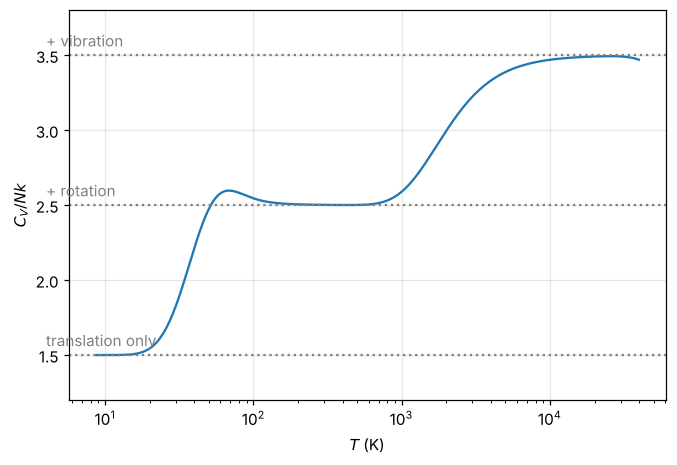

In [2]:
#| label: fig-h2-heat-capacity
#| caption: "Heat capacity of a diatomic gas (H₂-like, with rotational and vibrational temperatures 85 K and 6000 K) from the quantum partition function of thermo topic 6. Equipartition plateaus at 3/2, 5/2 and 7/2 appear only where kT is far from a level spacing."
T = np.logspace(0.5, 4.6, 400)
th_r, th_v = 85.0, 6000.0
def c_rot(T):                     # heat capacity of a rigid rotor (in units of k), by summing levels numerically
    l = np.arange(0, 60)[:, None]
    w = (2 * l + 1) * np.exp(-l * (l + 1) * th_r / T)
    E = l * (l + 1) * th_r
    Z = w.sum(0); E1 = (w * E).sum(0) / Z; E2 = (w * E**2).sum(0) / Z
    return (E2 - E1**2) / T**2
x = th_v / T
c_vib = x**2 * np.exp(x) / np.expm1(x)**2
fig, ax = plt.subplots()
ax.semilogx(T, 1.5 + c_rot(T) + c_vib)
for y, s in [(1.5, "translation only"), (2.5, "+ rotation"), (3.5, "+ vibration")]:
    ax.axhline(y, ls=":", color="gray"); ax.text(4, y + 0.06, s, color="gray")
ax.set_xlabel("$T$ (K)"); ax.set_ylabel("$C_V / Nk$"); ax.set_ylim(1.2, 3.8); plt.show()

(For real hydrogen the rotational curve is complicated by the two nuclear-spin forms, ortho- and para-hydrogen; the shape here ignores that.)

::::{prf:example} Level 1 rung: heating a gas in a box
:label: ex-gas-box-heat

How much heat raises 1.00 mol of helium and 1.00 mol of nitrogen from 20 °C to 80 °C in a rigid container?

:::{dropdown} Solution
At constant volume all the heat goes into internal energy, $Q = \Delta U = C_V\Delta T$. Helium has $f = 3$: $C_V = \tfrac32R = 12.5$ J/K, so $Q = 748$ J. Nitrogen at these temperatures has $f = 5$: $C_V = \tfrac52R = 20.8$ J/K, so $Q = 1.25$ kJ. The extra goes into rotation.
:::
::::

## The Maxwell Speed Distribution

Equipartition gives averages. The full distribution of speeds needs one more idea, the **Boltzmann factor** (thermo topic 6): the probability of a molecular state with energy $E$ is proportional to $e^{-E/kT}$. For velocities, $E = \tfrac12m(v_x^2 + v_y^2 + v_z^2)$, so the velocity distribution is a product of three Gaussians,

$$
p(\vec v)\,d^3v = \left(\frac{m}{2\pi kT}\right)^{3/2}e^{-mv^2/2kT}\,d^3v .
$$ (eq-maxwell-velocity)

To get the distribution of **speeds** $v = |\vec v|$, count all velocity vectors in a spherical shell of radius $v$ and thickness $dv$ in velocity space. The shell's volume is $4\pi v^2dv$:

$$
D(v) = 4\pi\left(\frac{m}{2\pi kT}\right)^{3/2}v^2e^{-mv^2/2kT} .
$$ (eq-maxwell-speed)

The $v^2$ is pure geometry: there are more ways to have a large speed (a bigger shell) even though each particular fast velocity is less likely. The product of rising $v^2$ and falling Gaussian gives the skewed peak.

The three characteristic speeds (T-M2 has the integrals) are

$$
v_{\max} = \sqrt{\frac{2kT}{m}},\qquad \bar v = \sqrt{\frac{8kT}{\pi m}},\qquad v_{\text{rms}} = \sqrt{\frac{3kT}{m}} ,
$$ (eq-maxwell-speeds)

in the ratio $1 : 1.128 : 1.225$.

In [3]:
# The moments, done symbolically
v, m_, k_, T_ = sp.symbols("v m k T", positive=True)
a = m_ / (2 * k_ * T_)
D = 4 * sp.pi * (a / sp.pi)**sp.Rational(3, 2) * v**2 * sp.exp(-a * v**2)
norm = sp.simplify(sp.integrate(D, (v, 0, sp.oo)))
vbar = sp.simplify(sp.integrate(v * D, (v, 0, sp.oo)))
v2 = sp.simplify(sp.integrate(v**2 * D, (v, 0, sp.oo)))
display(Math(r"\int_0^\infty D\,dv = " + sp.latex(norm)))
display(Math(r"\bar v = " + sp.latex(vbar) + r",\qquad \overline{v^2} = " + sp.latex(v2)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

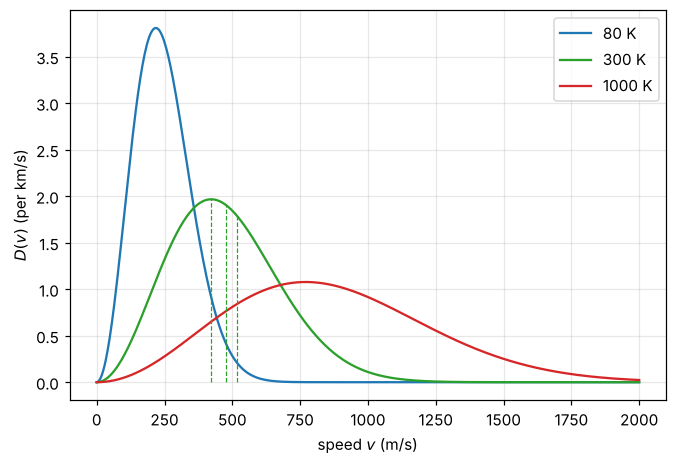

In [4]:
#| label: fig-maxwell-n2
#| caption: "Maxwell speed distributions for nitrogen at 80 K, 300 K and 1000 K. Higher temperature shifts the peak right and broadens it; the area under each curve stays 1. Vertical ticks mark the most probable, mean and rms speeds at 300 K."
m_N2 = 28 * 1.6605e-27
vv = np.linspace(0, 2000, 500)
def Dv(v, T, m=m_N2):
    return 4 * np.pi * (m / (2 * np.pi * k_B * T))**1.5 * v**2 * np.exp(-m * v**2 / (2 * k_B * T))
fig, ax = plt.subplots()
for T, col in [(80, "tab:blue"), (300, "tab:green"), (1000, "tab:red")]:
    ax.plot(vv, Dv(vv, T) * 1e3, color=col, label=f"{T} K")
T = 300
for s, lab in [(np.sqrt(2 * k_B * T / m_N2), r"$v_{\max}$"), (np.sqrt(8 * k_B * T / (np.pi * m_N2)), r"$\bar v$"),
               (np.sqrt(3 * k_B * T / m_N2), r"$v_{\rm rms}$")]:
    ax.plot([s, s], [0, Dv(s, T) * 1e3], color="tab:green", lw=0.8, ls="--")
ax.set_xlabel("speed $v$ (m/s)"); ax.set_ylabel("$D(v)$ (per km/s)"); ax.legend(); plt.show()

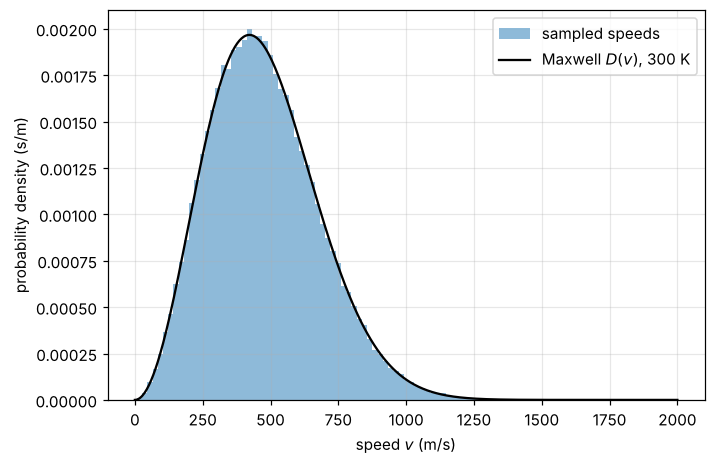

In [5]:
#| label: fig-maxwell-sampling
#| caption: "Sampling check. Draw 200 000 velocity vectors with each component Gaussian (variance kT/m), compute their speeds, and histogram them. The result matches D(v) with no fitting, showing the v² factor is just the geometry of speed shells."
rng = np.random.default_rng(1)
s = np.sqrt(k_B * 300 / m_N2)
vel = rng.normal(0, s, size=(200_000, 3))
speeds = np.linalg.norm(vel, axis=1)
fig, ax = plt.subplots()
ax.hist(speeds, bins=80, density=True, alpha=0.5, label="sampled speeds")
ax.plot(vv, Dv(vv, 300), color="k", label="Maxwell $D(v)$, 300 K")
ax.set_xlabel("speed $v$ (m/s)"); ax.set_ylabel("probability density (s/m)"); ax.legend(); plt.show()

::::{prf:example} Level 2 rung: what fraction of molecules is fast?
:label: ex-maxwell-tail

What fraction of nitrogen molecules at 300 K move faster than 1000 m/s? What fraction of hydrogen molecules in the upper atmosphere (1000 K) exceed Earth's escape speed, 11.2 km/s?

:::{dropdown} Solution
In terms of $x = v/v_{\max}$, the fraction above $x_0$ is

$$
\int_{x_0}^\infty\frac{4}{\sqrt\pi}x^2e^{-x^2}dx = \operatorname{erfc}(x_0) + \frac{2}{\sqrt\pi}x_0e^{-x_0^2} .
$$

Nitrogen at 300 K: $v_{\max} = 422$ m/s, $x_0 = 2.37$, fraction $\approx 1.1\%$.

Hydrogen ($m = 2$ u) at 1000 K: $v_{\max} = 2.87$ km/s, $x_0 = 3.90$, fraction $\approx 1.3\times10^{-6}$. Small, but molecules near the top of the atmosphere are constantly re-thermalized, so over geological time the fast tail is a steady leak. Nitrogen, 14 times heavier, has $x_0\approx 14.6$ and a fraction near $10^{-91}$: it stays.
:::
::::

In [6]:
from scipy.special import erfc
def frac_above(v0, T, m):
    x0 = v0 / np.sqrt(2 * k_B * T / m)
    return erfc(x0) + 2 / np.sqrt(np.pi) * x0 * np.exp(-x0**2)
u = 1.6605e-27
display(Math(rf"\text{{N}}_2,\ 300\ \text{{K}},\ v > 1000\ \text{{m/s}}:\quad {frac_above(1000, 300, 28 * u):.4f}"))
display(Math(rf"\text{{H}}_2,\ 1000\ \text{{K}},\ v > 11.2\ \text{{km/s}}:\quad {frac_above(11.2e3, 1000, 2 * u):.2e}"))
display(Math(rf"\text{{N}}_2,\ 1000\ \text{{K}},\ v > 11.2\ \text{{km/s}}:\quad {frac_above(11.2e3, 1000, 28 * u):.1e}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Looking Ahead to Level 3

Pathria starts where this chapter ends. Instead of a velocity distribution for one molecule, it counts states of the whole gas in a $6N$-dimensional **phase space** and builds the **partition function** $Z = \frac{1}{N!}\left(V/\lambda^3\right)^N$, where $\lambda = h/\sqrt{2\pi mkT}$ is the thermal wavelength. The $1/N!$ (the **Gibbs factor**) undoes overcounting of identical molecules; without it, entropy would fail to be extensive (the Gibbs paradox). Thermo topics 3 and 6 build the Level 2 versions of both ideas.

## Exercises

### Exercises

1. Find $v_{\text{rms}}$ for helium and for xenon (131 u) at 300 K. Which gas has the larger average kinetic energy per atom?
2. A tank holds 2.0 mol of an ideal diatomic gas at 300 K. Find its thermal energy, ignoring vibration. How does it change if the gas is helium instead?
3. Show that the most probable kinetic energy is $\tfrac12kT$, not $\tfrac12mv_{\max}^2 = kT$. (Find the distribution of $E = \tfrac12mv^2$ first.)
4. Sound in a gas travels at roughly the molecular speed. Estimate the ratio of sound speeds in helium and in nitrogen at the same temperature.
5. In the proof of {eq}`eq-kinetic-pressure`, we ignored collisions between molecules. Explain why the result is unchanged when they are included.

:::{dropdown} Hints
1. $v_{\text{rms}} = \sqrt{3kT/m}$. The kinetic energy depends only on $T$.
2. $U = \tfrac52NkT$ with $N = 2N_A$.
3. $D(E)\,dE = D(v)\,dv$ with $v = \sqrt{2E/m}$; you should find $D(E)\propto\sqrt E\,e^{-E/kT}$.
4. $v\propto1/\sqrt m$.
5. What do collisions do to the total momentum delivered to the wall per unit time?
:::

:::{dropdown} Answers
1. He: 1.37 km/s; Xe: 239 m/s. Same average kinetic energy, $\tfrac32kT = 6.2\times10^{-21}$ J.
2. $U = \tfrac52(2)(8.314)(300) = 12.5$ kJ. Helium: $\tfrac32$ instead of $\tfrac52$, so 7.5 kJ.
3. $D(E)\propto\sqrt Ee^{-E/kT}$ peaks where $\tfrac{1}{2E} = \tfrac{1}{kT}$, at $E = \tfrac12kT$. The Jacobian $dv/dE$ shifts the peak.
4. $\sqrt{28/4}\approx 2.6$ (measured: 1007/353 ≈ 2.9, the rest from different $C_P/C_V$).
5. Collisions conserve momentum and only shuffle which molecule carries it; in equilibrium the distribution of $v_x$ is unchanged, so the average momentum flux to the wall is the same.
:::

## Summary

- Temperature is what equalizes in thermal equilibrium; the ideal gas law $PV = NkT$ fixes the absolute scale.
- Kinetic theory: $PV = Nm\overline{v_x^2}$, so $\tfrac12m\overline{v^2} = \tfrac32kT$.
- Equipartition: $\tfrac12kT$ per quadratic degree of freedom, valid only when $kT$ exceeds the mode's level spacing.
- Maxwell distribution: Boltzmann factor times the $4\pi v^2$ shell volume. The three speeds are in ratio $1 : 1.128 : 1.225$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.